# PINN za prigušeni harmonijski oscilator — direktni i inverzni problem

**Cilj:** u jednačini prigušenog harmonijskog oscilatora parametar **μ je nepoznat** i određuje se **istovremenom minimizacijom gubitka na podacima i fizičkog gubitka**.

Notebook prati primer iz predavanja *ETH Zürich, Deep Learning in Scientific Computing 2023 — Physics-Informed Neural Networks: Applications* (originalni kod: [github.com/benmoseley/DLSC-2023](https://github.com/benmoseley/DLSC-2023), `lecture-5/PINN demo.ipynb`). Korišćene su iste vrednosti kao u originalnom primeru (δ = 2, ω₀ = 20, 30 kolokacionih tačaka, 15.000 koraka, λ = 10⁴, isto seme). Delovi 1, 4, 5 i 6 su dodati u odnosu na originalni kod.

**Potrebne biblioteke:** `numpy`, `matplotlib`, `scipy`, `torch`.

| Deo | Sadržaj |
|---|---|
| 0 | Prigušeni oscilator i njegovo tačno rešenje |
| 1 | Ograničenja obične mreže trenirane samo na podacima |
| 2 | PINN, **direktni problem**: rešavanje jednačine bez merenja |
| 3 | PINN, **inverzni problem**: određivanje nepoznatog μ iz šumnih merenja |
| 4 | Poređenje sa najboljom mogućom procenom (χ² fit) |
| 5 | Uticaj težine λ između gubitka na podacima i fizičkog gubitka |
| 6 | Otkrivanje jednačine (equation discovery) |
| 7 | Rezime |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import time

plt.rcParams["figure.figsize"] = (8, 4)
print("PyTorch:", torch.__version__)

PyTorch: 2.15.0+cu132


## 0. Prigušeni harmonijski oscilator

Sistem je teg na opruzi: posle pomeranja iz ravnoteže teg osciluje, a zbog trenja amplituda oscilacija postepeno opada.

**Jednačina kretanja** (drugi Njutnov zakon):
$$m\,\frac{d^2u}{dt^2} + \mu\,\frac{du}{dt} + k\,u = 0$$

| simbol | značenje | vrednost |
|---|---|---|
| $u(t)$ | položaj tega (odstupanje od ravnoteže) u trenutku $t$ | nepoznata funkcija |
| $\frac{du}{dt}$ | brzina | |
| $\frac{d^2u}{dt^2}$ | ubrzanje | |
| $m$ | masa | 1 |
| $k$ | krutost opruge (veće k → brže oscilacije) | 400 |
| $\mu$ | **koeficijent trenja** (veće μ → brže prigušenje) | 4 (u inverznom problemu nepoznat) |

Sila opruge ($-k u$) vraća teg ka ravnoteži, a sila trenja ($-\mu\, du/dt$) se suprotstavlja kretanju.

**Početni uslovi:** $u(0) = 1$ (početni pomeraj) i $\dfrac{du}{dt}(0) = 0$ (početak iz mirovanja).

**Tačno rešenje** za podkritično prigušenje ($\delta = \mu/2m < \omega_0 = \sqrt{k/m}$):
$$u(t) = e^{-\delta t}\, 2A \cos(\phi + \omega t), \quad \omega = \sqrt{\omega_0^2 - \delta^2}$$
- $e^{-\delta t}$ opisuje opadanje amplitude (prigušenje),
- $\cos(\omega t)$ opisuje oscilovanje.

U primeru je $\omega_0 = 20$, $\delta = 2$.

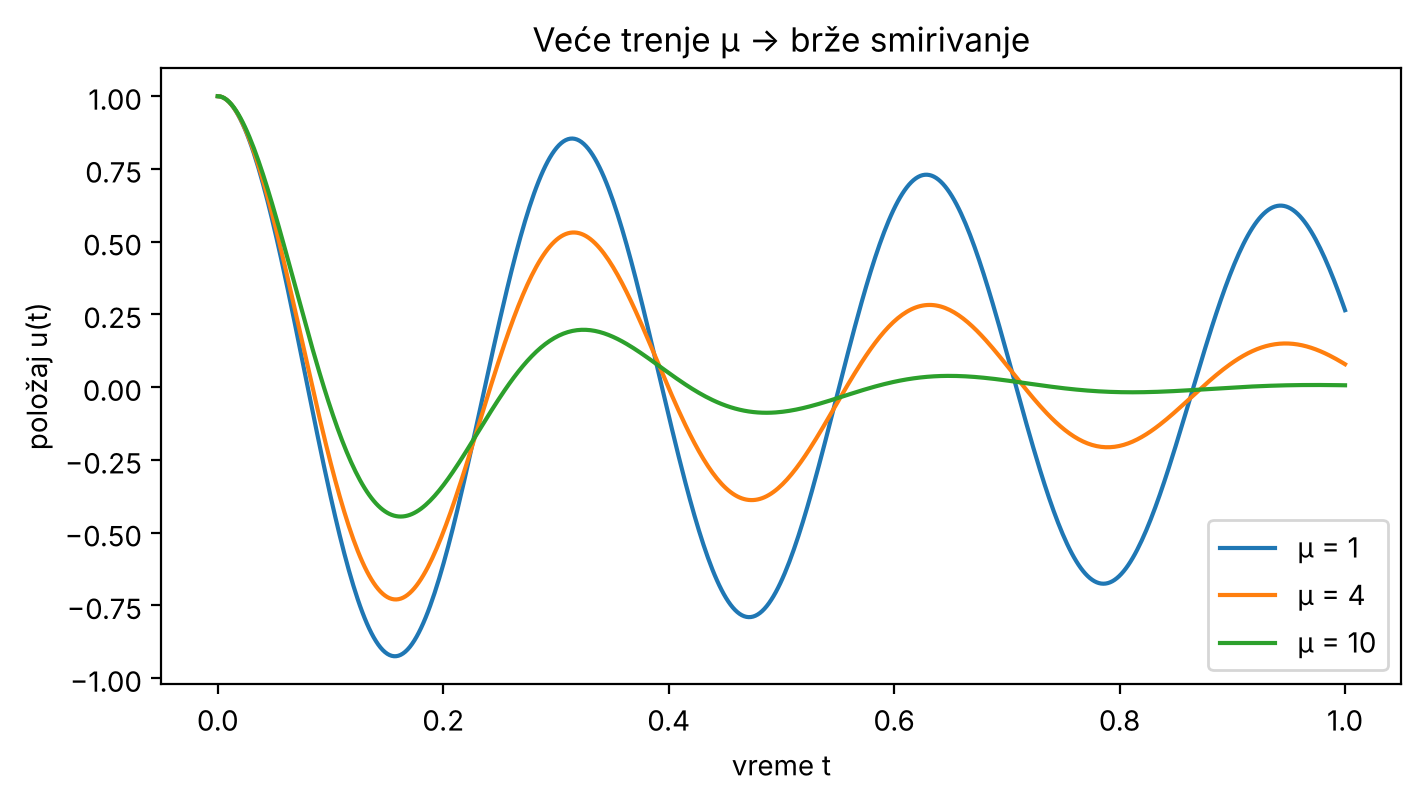

In [2]:
m_, k_ = 1.0, 400.0
mu_tacno = 4.0
w0 = np.sqrt(k_ / m_)            # 20

def tacno_resenje(t, mu=mu_tacno):
    d = mu / (2 * m_)
    w = np.sqrt(w0**2 - d**2)
    phi = np.arctan(-d / w)
    A = 1 / (2 * np.cos(phi))
    return np.exp(-d * t) * 2 * A * np.cos(phi + w * t)

t = np.linspace(0, 1, 500)
for mu in [1, 4, 10]:
    plt.plot(t, tacno_resenje(t, mu), label=f"μ = {mu}")
plt.xlabel("vreme t"); plt.ylabel("položaj u(t)"); plt.legend()
plt.title("Veće trenje μ → brže smirivanje"); plt.show()

## 1. Ograničenja obične mreže

Obična neuronska mreža uči isključivo iz podataka. Ako su merenja dostupna samo za **prvu trećinu** vremenskog intervala, ponašanje mreže van tog intervala nije ničim ograničeno.

Arhitektura: ulaz $t$ → 3 skrivena sloja po 32 neurona sa tanh aktivacijom → izlaz $u$.

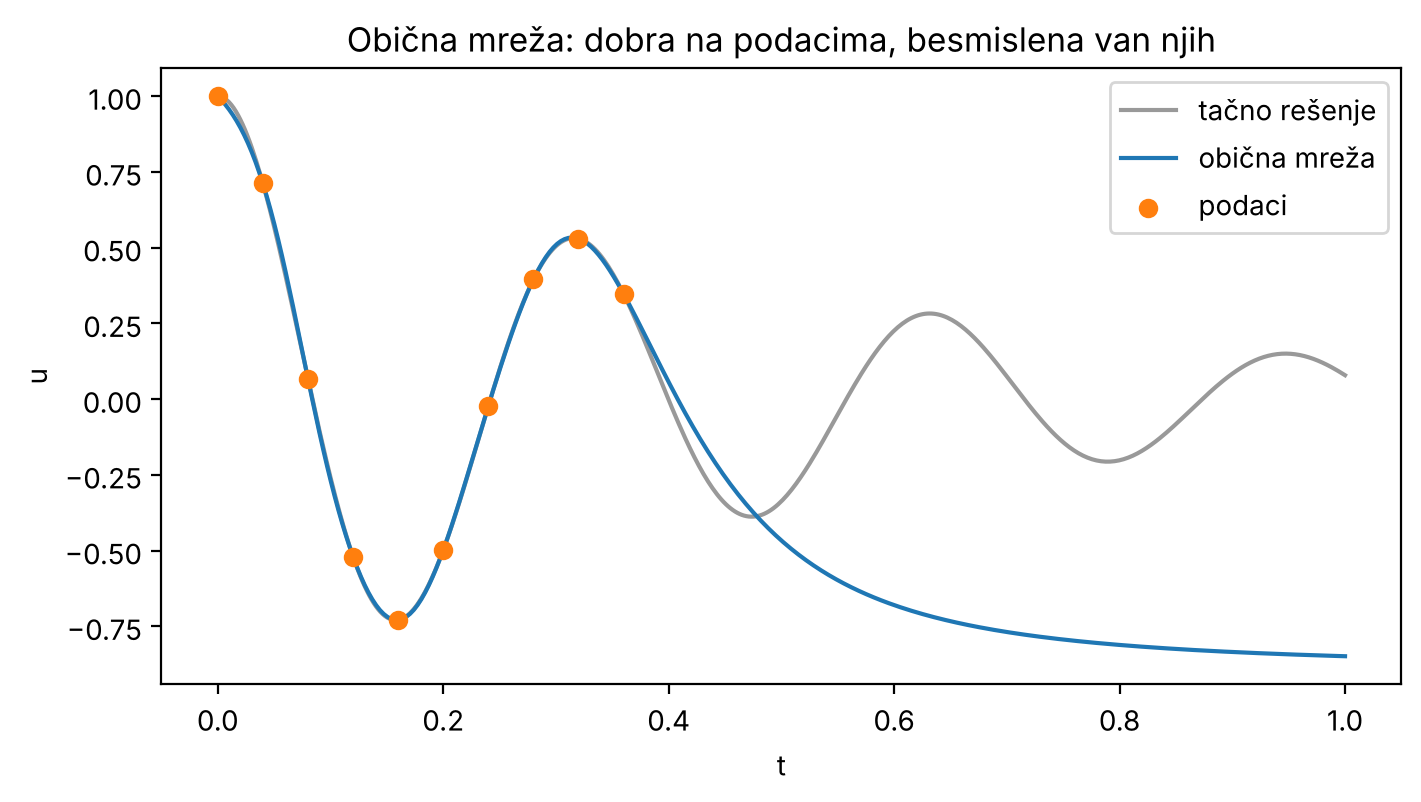

In [3]:
class FCN(nn.Module):
    # Potpuno povezana mreža: t -> u(t)
    def __init__(self, h=32, slojeva=3):
        super().__init__()
        layers = [nn.Linear(1, h), nn.Tanh()]
        for _ in range(slojeva - 1):
            layers += [nn.Linear(h, h), nn.Tanh()]
        layers += [nn.Linear(h, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, t):
        return self.net(t)

torch.manual_seed(123)
t_podaci = np.linspace(0, 0.36, 10).reshape(-1, 1)       # merenja samo do t = 0.36
u_podaci = tacno_resenje(t_podaci)
T_pod = torch.tensor(t_podaci, dtype=torch.float32)
U_pod = torch.tensor(u_podaci, dtype=torch.float32)

nn_obicna = FCN()
opt = torch.optim.Adam(nn_obicna.parameters(), lr=1e-3)
for i in range(5000):
    loss = torch.mean((nn_obicna(T_pod) - U_pod) ** 2)        # samo gubitak na podacima (MSE)
    opt.zero_grad(); loss.backward(); opt.step()

T_ceo = torch.linspace(0, 1, 300).view(-1, 1)
plt.plot(t, tacno_resenje(t), "k", alpha=0.4, label="tačno rešenje")
plt.plot(T_ceo, nn_obicna(T_ceo).detach(), "C0", label="obična mreža")
plt.scatter(t_podaci, u_podaci, color="C1", zorder=3, label="podaci")
plt.xlabel("t"); plt.ylabel("u"); plt.legend()
plt.title("Obična mreža: dobra na podacima, besmislena van njih"); plt.show()

## 2. PINN — direktni problem (bez merenja)

**Ideja PINN-a:** mreža $u_\theta(t)$ treba da **zadovolji jednačinu** i početne uslove. Funkcija gubitka ima tri dela:

$$\mathcal{L} = \underbrace{(u_\theta(0) - 1)^2}_{\text{početni položaj}} + \lambda_1 \underbrace{\left(\frac{du_\theta}{dt}(0)\right)^2}_{\text{početna brzina}} + \lambda_2 \underbrace{\frac{1}{N}\sum_{j}\left(\frac{d^2u_\theta}{dt^2} + \mu \frac{du_\theta}{dt} + k\,u_\theta\right)^2_{t_j}}_{\text{rezidual jednačine (fizički gubitak)}}$$

- **Rezidual** je odstupanje leve strane jednačine od nule; za rešenje koje tačno zadovoljava jednačinu jednak je nuli.
- Računa se u **kolokacionim tačkama** $t_j$ (ovde 30 tačaka u [0, 1]), u kojima nisu potrebna merenja.
- Izvodi $du/dt$ i $d^2u/dt^2$ računaju se **automatskim diferenciranjem** (`torch.autograd.grad`).
- Težine $\lambda_1 = 10^{-1}$ i $\lambda_2 = 10^{-4}$ izjednačavaju redove veličine pojedinih delova (rezidual je reda stotina jer je $k = 400$).

korak     0: početni uslovi = 9.39e-01, fizika = 8.25e+02


korak  5000: početni uslovi = 8.87e-05, fizika = 7.92e+01


korak 10000: početni uslovi = 8.64e-05, fizika = 2.87e+01


korak 15000: početni uslovi = 6.33e-07, fizika = 4.86e+00
Trening: 35 s
Najveća greška u odnosu na tačno rešenje: 0.017


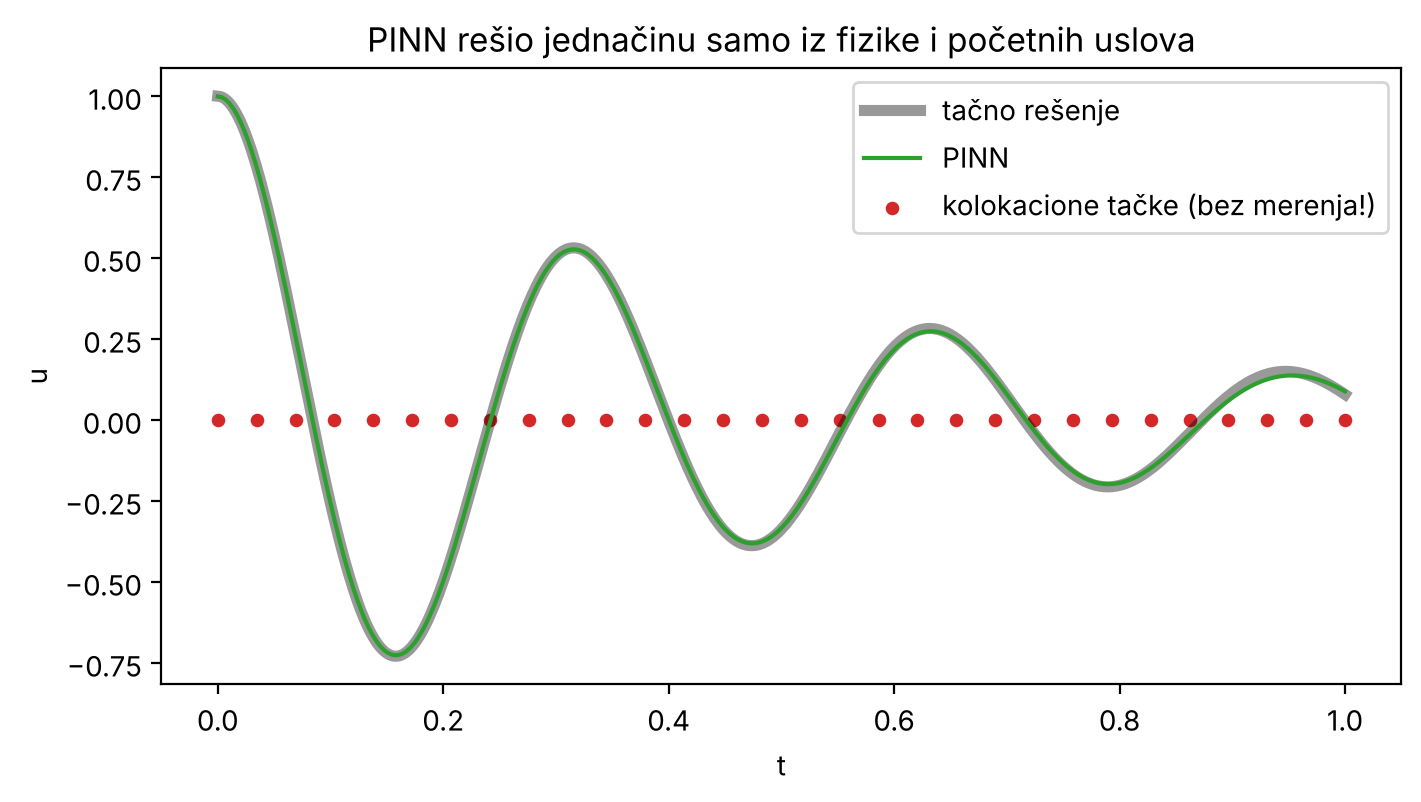

In [4]:
def izvod(u, t):
    # du/dt preko automatskog diferenciranja; create_graph=True omogućava i drugi izvod
    return torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)[0]

torch.manual_seed(123)
pinn = FCN()
t_pocetak = torch.zeros(1, 1, requires_grad=True)                       # t = 0
t_kol = torch.linspace(0, 1, 30).view(-1, 1).requires_grad_(True)      # kolokacione tačke
opt = torch.optim.Adam(pinn.parameters(), lr=1e-3)
lam1, lam2 = 1e-1, 1e-4

t0 = time.time()
for i in range(15001):
    # početni uslovi
    u0 = pinn(t_pocetak)
    du0 = izvod(u0, t_pocetak)
    loss_poc = (u0 - 1) ** 2 + lam1 * du0 ** 2
    # fizika (rezidual jednačine)
    u = pinn(t_kol)
    du = izvod(u, t_kol)
    d2u = izvod(du, t_kol)
    loss_fiz = torch.mean((m_ * d2u + mu_tacno * du + k_ * u) ** 2)
    loss = loss_poc + lam2 * loss_fiz
    opt.zero_grad(); loss.sum().backward(); opt.step()
    if i % 5000 == 0:
        print(f"korak {i:5d}: početni uslovi = {loss_poc.item():.2e}, fizika = {loss_fiz.item():.2e}")
print(f"Trening: {time.time() - t0:.0f} s")

u_pinn = pinn(T_ceo).detach().numpy().ravel()
print(f"Najveća greška u odnosu na tačno rešenje: {np.max(np.abs(u_pinn - tacno_resenje(T_ceo.numpy().ravel()))):.3f}")
plt.plot(t, tacno_resenje(t), "k", alpha=0.4, lw=4, label="tačno rešenje")
plt.plot(T_ceo, u_pinn, "C2", label="PINN")
plt.scatter(t_kol.detach(), np.zeros(30), s=15, color="C3", label="kolokacione tačke (bez merenja!)")
plt.xlabel("t"); plt.ylabel("u"); plt.legend()
plt.title("PINN rešio jednačinu samo iz fizike i početnih uslova"); plt.show()

## 3. PINN — inverzni problem: nepoznato μ

**Postavka:** dostupno je **40 šumnih merenja** položaja (šum σ = 0,04); oblik jednačine i $k$ su poznati, ali **μ nije**.

μ se uvodi kao **parametar koji se uči**, zajedno sa težinama mreže (`nn.Parameter`). Optimizator menja i mrežu i μ tako da istovremeno:
- mreža prolazi kroz merenja (**gubitak na podacima**),
- mreža zadovoljava jednačinu sa trenutnom vrednošću μ (**fizički gubitak**).

$$\mathcal{L}(\theta, \mu) = \underbrace{\frac{1}{N_f}\sum_j \left(\frac{d^2u_\theta}{dt^2} + \mu \frac{du_\theta}{dt} + k\,u_\theta\right)^2_{t_j}}_{\text{fizički gubitak}} + \lambda \underbrace{\frac{1}{N_d}\sum_i \left(u_\theta(t_i) - u_i^{\text{obs}}\right)^2}_{\text{gubitak na podacima}}$$

Za pogrešno μ ne postoji funkcija koja istovremeno prolazi kroz podatke i zadovoljava jednačinu, pa gubitak ostaje veliki; samo vrednost blizu prave omogućava da oba dela budu mala. Početni uslovi ovde nisu potrebni jer ih zamenjuju merenja.

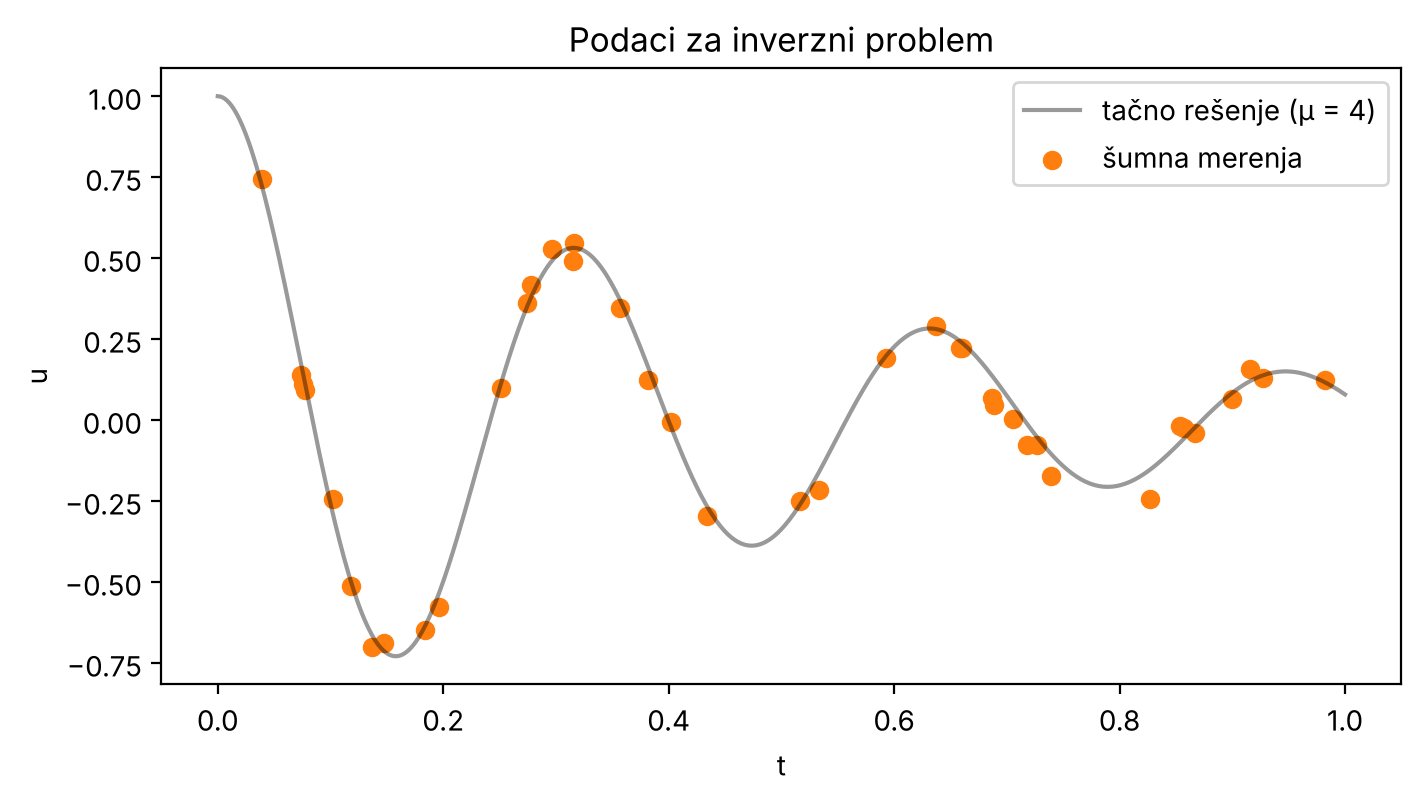

In [5]:
# Isti podaci kao u originalnom primeru (Moseley, DLSC 2023, lecture-5)
torch.manual_seed(123)
sigma = 0.04
T_obs = torch.rand(40).view(-1, 1)                                    # 40 nasumičnih trenutaka u [0, 1]
U_obs = torch.tensor(tacno_resenje(T_obs.numpy()), dtype=torch.float32) + sigma * torch.randn_like(T_obs)  # merenja sa šumom
t_obs, u_obs = T_obs.numpy(), U_obs.numpy()

plt.plot(t, tacno_resenje(t), "k", alpha=0.4, label="tačno rešenje (μ = 4)")
plt.scatter(t_obs, u_obs, color="C1", label="šumna merenja")
plt.xlabel("t"); plt.ylabel("u"); plt.legend(); plt.title("Podaci za inverzni problem"); plt.show()

In [6]:
def inverzni_pinn(lam=1e4, n_kol=30, koraka=15001, seed=123, pratimo=True):
    torch.manual_seed(seed)
    pinn = FCN()
    mu = nn.Parameter(torch.zeros(1))                    # početni pokušaj: μ = 0
    t_kol = torch.linspace(0, 1, n_kol).view(-1, 1).requires_grad_(True)
    opt = torch.optim.Adam(list(pinn.parameters()) + [mu], lr=1e-3)   # uče se i mreža i μ
    istorija_mu = []
    for i in range(koraka):
        u = pinn(t_kol); du = izvod(u, t_kol); d2u = izvod(du, t_kol)
        loss_fiz = torch.mean((m_ * d2u + mu * du + k_ * u) ** 2)
        loss_pod = torch.mean((pinn(T_obs) - U_obs) ** 2)
        loss = loss_fiz + lam * loss_pod
        opt.zero_grad(); loss.backward(); opt.step()
        istorija_mu.append(mu.item())
        if pratimo and i % 3000 == 0:
            print(f"korak {i:5d}: μ = {mu.item():6.3f}, fizika = {loss_fiz.item():8.2f}, podaci = {loss_pod.item():.5f}")
    return pinn, mu.item(), istorija_mu

t0 = time.time()
pinn_inv, mu_nauceno, ist_mu = inverzni_pinn()
print(f"\nNaučeno μ = {mu_nauceno:.3f}   (tačno: {mu_tacno})   — trening {time.time()-t0:.0f} s")

korak     0: μ = -0.001, fizika =   804.16, podaci = 0.12169


korak  3000: μ =  0.157, fizika =     1.19, podaci = 0.11204


korak  6000: μ =  4.926, fizika =    82.79, podaci = 0.00786


korak  9000: μ =  5.453, fizika =     6.17, podaci = 0.00278


korak 12000: μ =  4.168, fizika =     3.50, podaci = 0.00129


korak 15000: μ =  4.044, fizika =     2.67, podaci = 0.00126

Naučeno μ = 4.044   (tačno: 4.0)   — trening 32 s


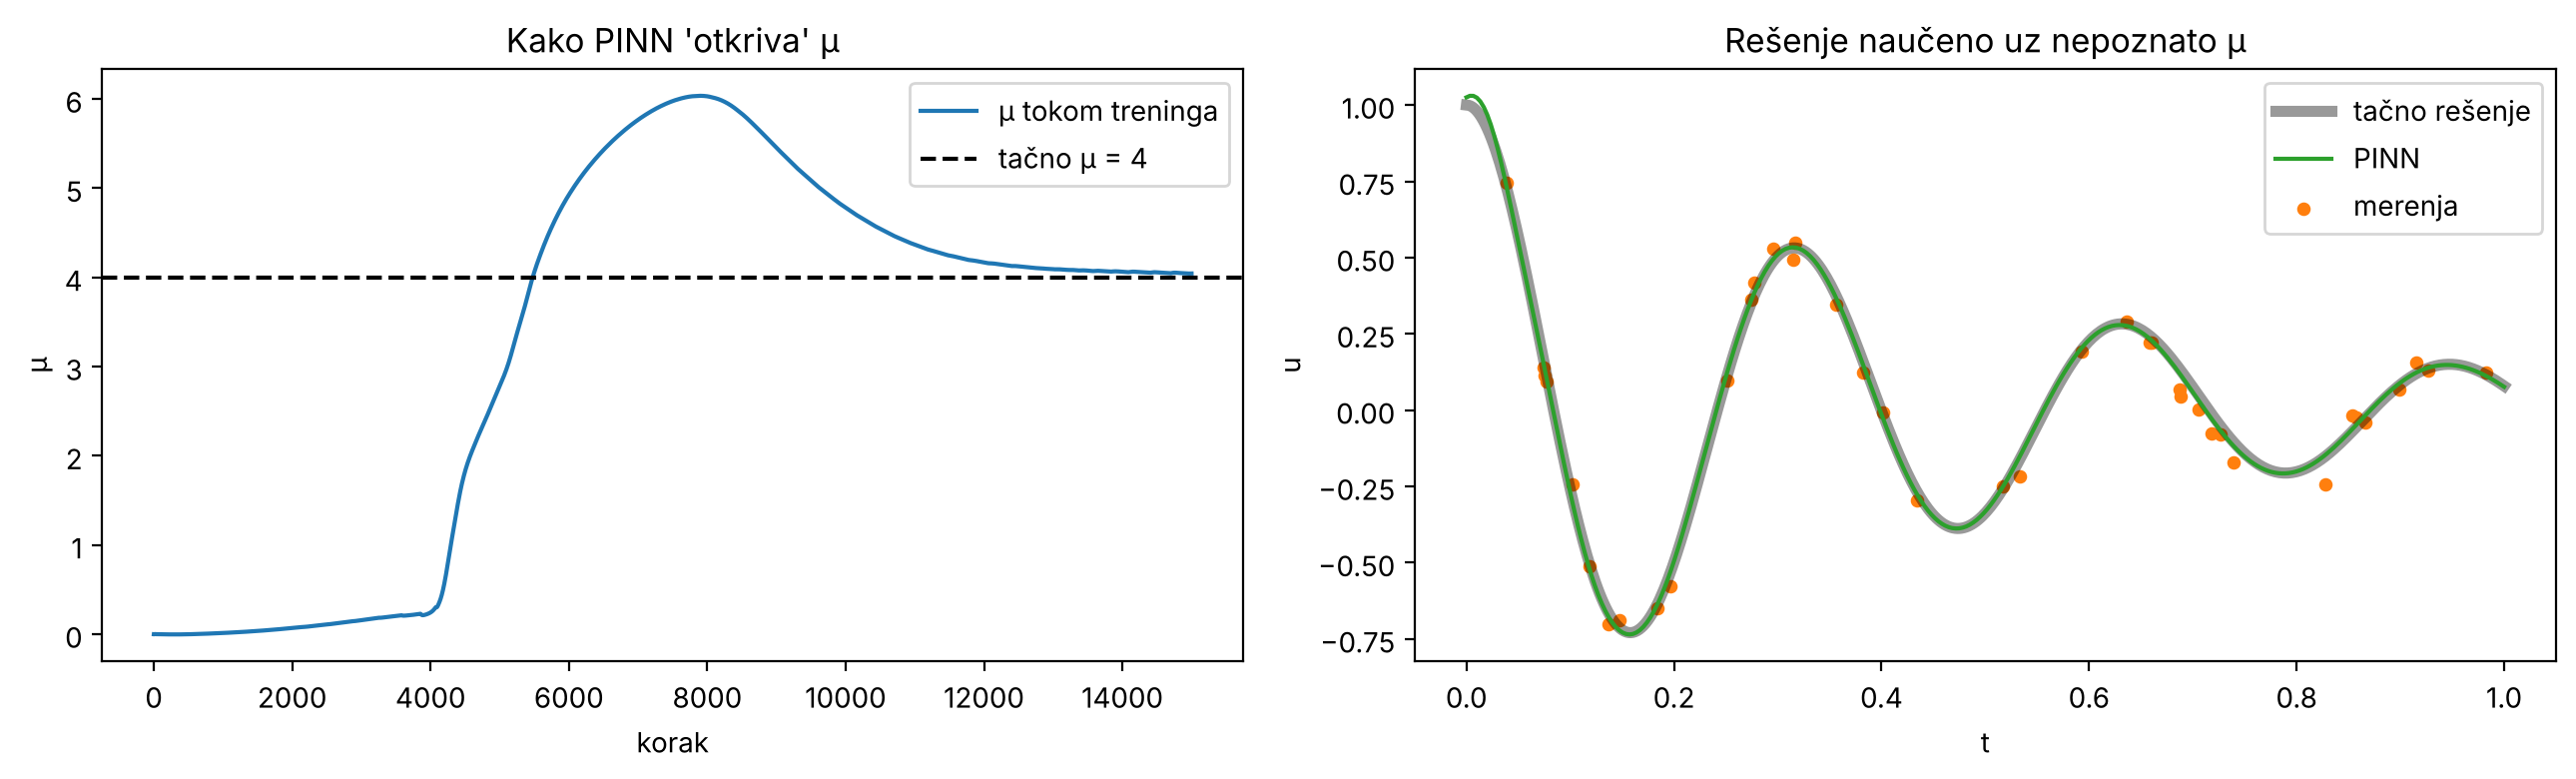

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(ist_mu, label="μ tokom treninga")
axs[0].axhline(mu_tacno, color="k", ls="--", label="tačno μ = 4")
axs[0].set_xlabel("korak"); axs[0].set_ylabel("μ"); axs[0].legend(); axs[0].set_title("Kako PINN 'otkriva' μ")

axs[1].plot(t, tacno_resenje(t), "k", alpha=0.4, lw=4, label="tačno rešenje")
axs[1].plot(T_ceo, pinn_inv(T_ceo).detach(), "C2", label="PINN")
axs[1].scatter(t_obs, u_obs, color="C1", s=15, label="merenja")
axs[1].set_xlabel("t"); axs[1].set_ylabel("u"); axs[1].legend(); axs[1].set_title("Rešenje naučeno uz nepoznato μ")
plt.tight_layout(); plt.show()

## 4. Poređenje sa najboljom mogućom procenom

Zbog šuma u podacima **ni idealna metoda ne može dati tačno μ = 4**. Gornja granica tačnosti procenjuje se klasičnim fitom, uz pretpostavku da je poznata tačna formula rešenja $u(t; \mu)$. Minimizuje se
$$\chi^2(\mu) = \sum_i \frac{\left(u_i^{\text{obs}} - u(t_i; \mu)\right)^2}{\sigma^2}$$
Najbolja vrednost μ je minimum χ², a **1σ interval** čine vrednosti za koje je $\chi^2 \le \chi^2_{\min} + 1$ (pravilo za jedan parametar).

Ova procena je referentna za date podatke. PINN ne koristi formulu rešenja, već samo jednačinu.

Najbolje μ iz χ² (zna formulu rešenja): 3.898  (1σ interval: 3.779 – 4.020)
PINN (zna samo jednačinu):              4.044
Tačno μ:                                4.000


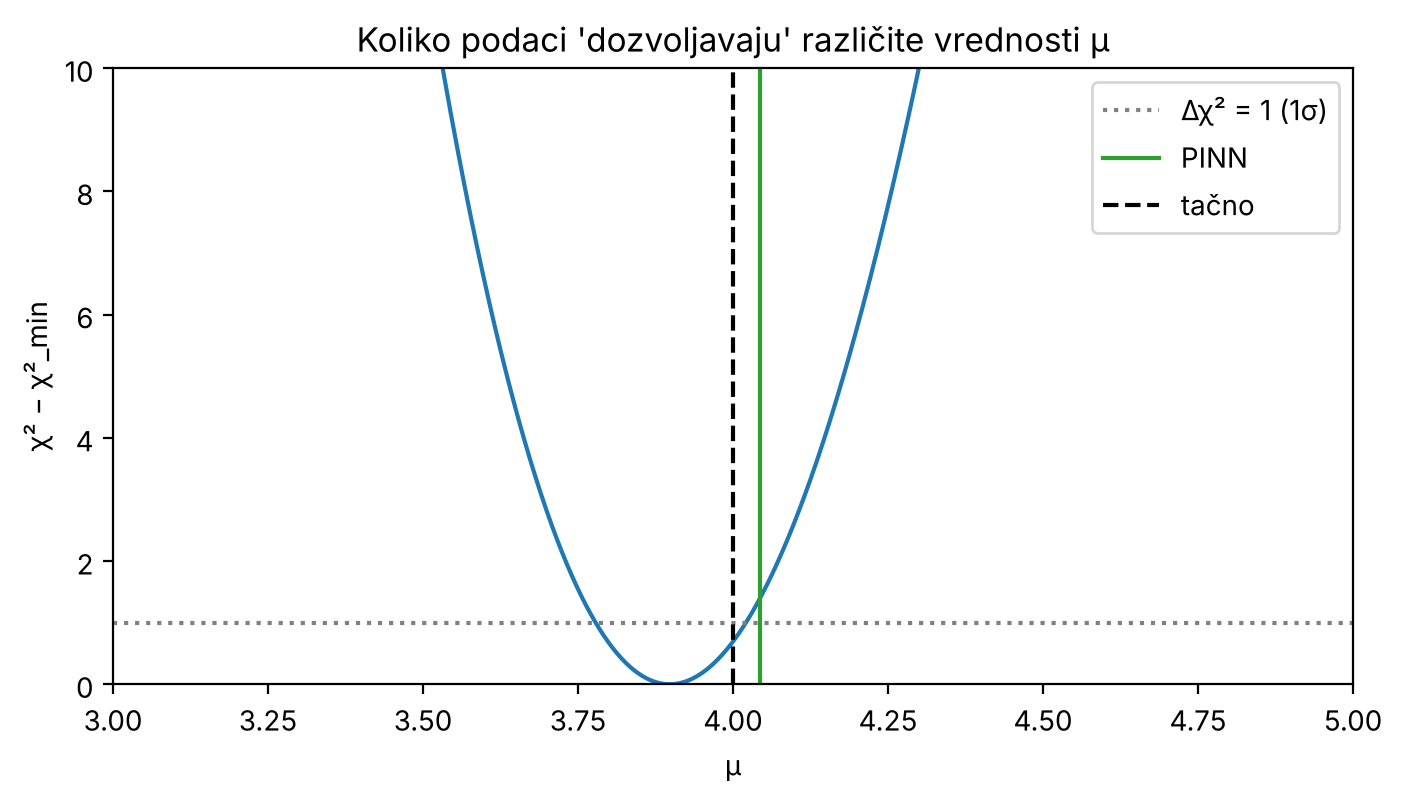

In [8]:
from scipy.optimize import minimize_scalar
chi2 = lambda mu: np.sum((u_obs - tacno_resenje(t_obs, mu)) ** 2) / sigma**2
res = minimize_scalar(chi2, bounds=(0, 10), method="bounded")
mus = np.linspace(2, 6, 4001)
c = np.array([chi2(x) for x in mus])
u_intervalu = mus[c <= res.fun + 1]

print(f"Najbolje μ iz χ² (zna formulu rešenja): {res.x:.3f}  (1σ interval: {u_intervalu.min():.3f} – {u_intervalu.max():.3f})")
print(f"PINN (zna samo jednačinu):              {mu_nauceno:.3f}")
print(f"Tačno μ:                                {mu_tacno:.3f}")

plt.plot(mus, c - res.fun)
plt.axhline(1, color="gray", ls=":", label="Δχ² = 1 (1σ)")
plt.axvline(mu_nauceno, color="C2", label="PINN")
plt.axvline(mu_tacno, color="k", ls="--", label="tačno")
plt.ylim(0, 10); plt.xlim(3, 5)
plt.xlabel("μ"); plt.ylabel("χ² − χ²_min"); plt.legend()
plt.title("Koliko podaci 'dozvoljavaju' različite vrednosti μ"); plt.show()

Kriva pokazuje koliko se fit pogoršava pri udaljavanju od najbolje vrednosti μ. Vrednosti ispod sive linije pripadaju 1σ intervalu i podjednako su saglasne sa podacima. Ako je vrednost dobijena PINN-om blizu tog intervala, PINN je iskoristio gotovo svu informaciju sadržanu u podacima. Mala razlika potiče od toga što PINN istovremeno uči celu funkciju $u(t)$, a ne samo jedan parametar.

## 5. Uticaj težine λ između podataka i fizike

λ određuje relativni značaj gubitka na podacima u odnosu na fizički gubitak.
- **Mala λ:** podaci gotovo ne utiču na trening, pa nema informacije o μ.
- **Velika λ:** mreža prati šum u podacima, a fizički gubitak ima mali uticaj.
- Između ovih krajnosti postoji ravnoteža.

(Izvršavanje traje nekoliko minuta — tri treninga.)

λ =    1e+02:  μ = -0.277   (32 s)


λ =    1e+04:  μ =  4.044   (30 s)


λ =    1e+06:  μ =  3.817   (29 s)


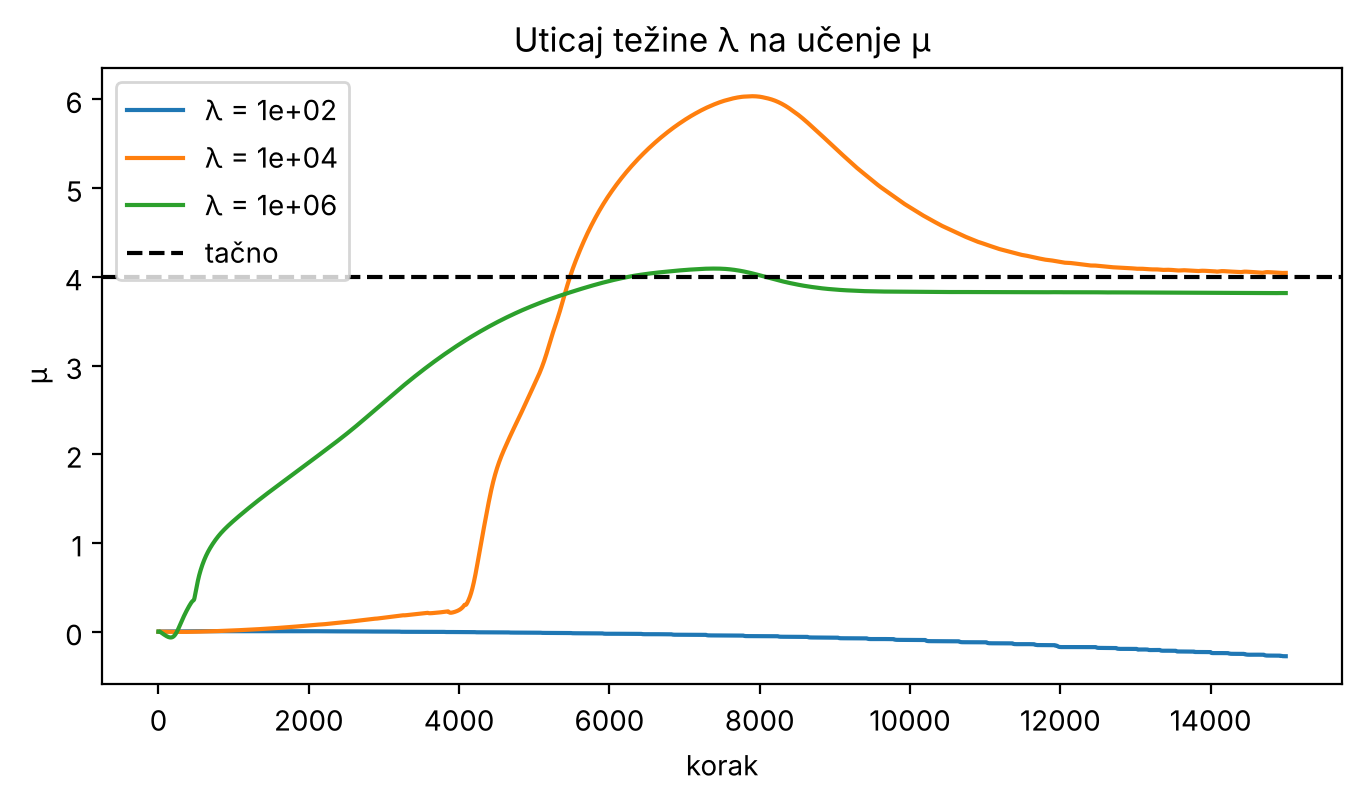

In [9]:
rezultati = {}
for lam in [1e2, 1e4, 1e6]:
    t0 = time.time()
    _, mu_l, ist = inverzni_pinn(lam=lam, pratimo=False)
    rezultati[lam] = ist
    print(f"λ = {lam:8.0e}:  μ = {mu_l:6.3f}   ({time.time()-t0:.0f} s)")

for lam, ist in rezultati.items():
    plt.plot(ist, label=f"λ = {lam:.0e}")
plt.axhline(mu_tacno, color="k", ls="--", label="tačno")
plt.xlabel("korak"); plt.ylabel("μ"); plt.legend(); plt.title("Uticaj težine λ na učenje μ"); plt.show()

## 6. Otkrivanje jednačine (equation discovery)

Kada nije poznat ni *oblik* jednačine, pretpostavlja se da je ona linearna kombinacija članova iz unapred zadate **biblioteke**:
$$\frac{d^2u}{dt^2} + c_0\,u + c_1\,\frac{du}{dt} + c_2\,u^3 = 0$$
- Koeficijenti $c_0, c_1, c_2$ su **svi nepoznati** i uče se zajedno sa mrežom.
- $u^3$ je kandidat koji ne postoji u pravoj jednačini, pa se očekuje $c_2 \approx 0$.
- Tačne vrednosti: $c_0 = k/m = 400$, $c_1 = \mu/m = 4$, $c_2 = 0$.
- Koeficijent uz $d^2u/dt^2$ fiksiran je na 1, jer bi inače trivijalno rešenje (svi koeficijenti nula) zadovoljilo jednačinu.
- **L1 regularizacija** $|c_1| + |c_2|$ potiskuje nepotrebne članove ka nuli (retkost, *sparsity*).
- Koeficijenti imaju veću stopu učenja (0,1), jer $c_0$ treba da dostigne vrednost 400.

In [10]:
torch.manual_seed(123)
pinn_eq = FCN()
c = nn.Parameter(torch.zeros(3))                              # [c0 (uz u), c1 (uz du/dt), c2 (uz u^3)]
t_kol = torch.linspace(0, 1, 30).view(-1, 1).requires_grad_(True)
opt = torch.optim.Adam([{"params": pinn_eq.parameters(), "lr": 1e-3},
                        {"params": [c], "lr": 1e-1}])         # različite stope učenja za mrežu i koeficijente
t0 = time.time()
for i in range(20001):
    u = pinn_eq(t_kol); du = izvod(u, t_kol); d2u = izvod(du, t_kol)
    rezidual = d2u + c[0] * u + c[1] * du + c[2] * u**3
    loss = (torch.mean(rezidual**2)
            + 1e4 * torch.mean((pinn_eq(T_obs) - U_obs) ** 2)
            + 1e-1 * c[1:].abs().sum())                         # L1: nepotrebni članovi ka nuli
    opt.zero_grad(); loss.backward(); opt.step()
    if i % 5000 == 0:
        print(f"korak {i:5d}: c0 = {c[0].item():7.2f}, c1 = {c[1].item():5.2f}, c2 = {c[2].item():6.3f}")
print(f"\nOtkrivena jednačina: u'' + {c[0].item():.1f}·u + {c[1].item():.2f}·u' + {c[2].item():.3f}·u³ = 0")
print(f"Tačna jednačina:     u'' + 400.0·u + 4.00·u' + 0.000·u³ = 0      ({time.time()-t0:.0f} s)")

korak     0: c0 =    0.10, c1 =  0.10, c2 =  0.100


korak  5000: c0 =  400.75, c1 =  5.12, c2 =  0.015


korak 10000: c0 =  402.95, c1 =  4.41, c2 =  0.002


korak 15000: c0 =  402.75, c1 =  4.24, c2 = -0.009


korak 20000: c0 =  402.76, c1 =  4.15, c2 =  0.010

Otkrivena jednačina: u'' + 402.8·u + 4.15·u' + 0.010·u³ = 0
Tačna jednačina:     u'' + 400.0·u + 4.00·u' + 0.000·u³ = 0      (44 s)


## 7. Rezime

1. **Obična mreža** uči samo iz podataka i nema ograničenja van njih.
2. **PINN, direktni problem:** mreža rešava diferencijalnu jednačinu bez ijednog merenja, samo na osnovu jednačine i početnih uslova.
3. **PINN, inverzni problem:** nepoznati fizički parametar μ uvodi se kao `nn.Parameter` i uči zajedno sa mrežom minimizacijom **fizičkog gubitka + λ · gubitka na podacima**.
4. Rezultat se poredi sa najboljom mogućom procenom (χ² fit); šum u podacima određuje granicu tačnosti.
5. **λ je ključan hiperparametar** koji određuje ravnotežu između podataka i fizike.
6. **Otkrivanje jednačine** koristi isti princip, uz učenje koeficijenata cele biblioteke članova i L1 regularizaciju.

**Ograničenje:** PINN ne daje nesigurnost za μ, već jednu vrednost (analogno MAP proceni). Za procenu nesigurnosti mogu se koristiti emcee (ako je jednačinu moguće rešiti numerički), Flow Matching sa simulatorom ili ansambl PINN-ova sa različitim početnim težinama.

**Veza sa statističkim fitom:** gubitak na podacima je MSE; uz poznatu σ to je $\chi^2 \cdot \sigma^2 / N$. Težina λ zato ima statističko značenje: odnos poverenja u merenja i u jednačinu.

**Otvorena pitanja:**
1. Izbor λ u praksi i mogućnost da se poveže sa nesigurnošću merenja σ.
2. Procena nesigurnosti za μ (ansambl, Bajesovski PINN, Flow Matching).
3. Poređenje sa Flow Matching pristupom na istom problemu.